In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams

rcParams['font.sans-serif'] = ['SimHei']

df = pd.read_csv("D:/projects/titanic-eda/data/titanic.csv")

df.info()
df.head()


<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 56.1 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 数据初步查看与缺失值分析
观察 `df.info()` 的输出，发现数据集存在不同程度的缺失情况：
- **Age（年龄）**：332个有效值，缺失 86 个（约 21%）。属于中度缺失，不能直接删除，后续考虑用**中位数**进行填充。
- **Fare（票价）**：417个有效值，仅缺失 1 个。后续可以填充中位数。
- **Cabin（船舱号）**：只有 91 个有效值，缺失了 327 个（近 78%）。缺失非常严重，直接填充没有意义，后续考虑**直接删掉这一列**，
**下一步行动**：针对上述情况，编写代码进行针对性的数据清洗。

In [2]:
age_median=df['Age'].median()
df['Age']=df['Age'].fillna(age_median)
fare_median=df['Fare'].median()
df['Fare']=df['Fare'].fillna(fare_median)
df=df.dropna(subset=['Cabin'])
df.info()

<class 'pandas.DataFrame'>
Index: 91 entries, 12 to 414
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  91 non-null     int64  
 1   Survived     91 non-null     int64  
 2   Pclass       91 non-null     int64  
 3   Name         91 non-null     str    
 4   Sex          91 non-null     str    
 5   Age          91 non-null     float64
 6   SibSp        91 non-null     int64  
 7   Parch        91 non-null     int64  
 8   Ticket       91 non-null     str    
 9   Fare         91 non-null     float64
 10  Cabin        91 non-null     str    
 11  Embarked     91 non-null     str    
dtypes: float64(2), int64(5), str(5)
memory usage: 13.7 KB


In [3]:
df.duplicated().sum()
df['Sex'] = df['Sex'].astype('category')
df['Embarked'] = df['Embarked'].astype('category')
df['Pclass'] = df['Pclass'].astype('category')
df.info()
df.head()

<class 'pandas.DataFrame'>
Index: 91 entries, 12 to 414
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  91 non-null     int64   
 1   Survived     91 non-null     int64   
 2   Pclass       91 non-null     category
 3   Name         91 non-null     str     
 4   Sex          91 non-null     category
 5   Age          91 non-null     float64 
 6   SibSp        91 non-null     int64   
 7   Parch        91 non-null     int64   
 8   Ticket       91 non-null     str     
 9   Fare         91 non-null     float64 
 10  Cabin        91 non-null     str     
 11  Embarked     91 non-null     category
dtypes: category(3), float64(2), int64(4), str(3)
memory usage: 11.3 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
12,904,1,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23.0,1,0,21228,82.2667,B45,S
14,906,1,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.1750,E31,S
24,916,1,1,"Ryerson, Mrs. Arthur Larned (Emily Maria Borie)",female,48.0,1,3,PC 17608,262.3750,B57 B59 B63 B66,C
26,918,1,1,"Ostby, Miss. Helene Ragnhild",female,22.0,0,1,113509,61.9792,B36,C
28,920,0,1,"Brady, Mr. John Bertram",male,41.0,0,0,113054,30.5000,A21,S


In [4]:
print(df.groupby('Sex')['Survived'].mean())
print(df.groupby('Pclass')['Survived'].mean())

Sex
female    1.0
male      0.0
Name: Survived, dtype: float64
Pclass
1    0.500000
2    0.428571
3    0.250000
Name: Survived, dtype: float64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15868\3419270194.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[1], palette="pastel")


图片已保存！


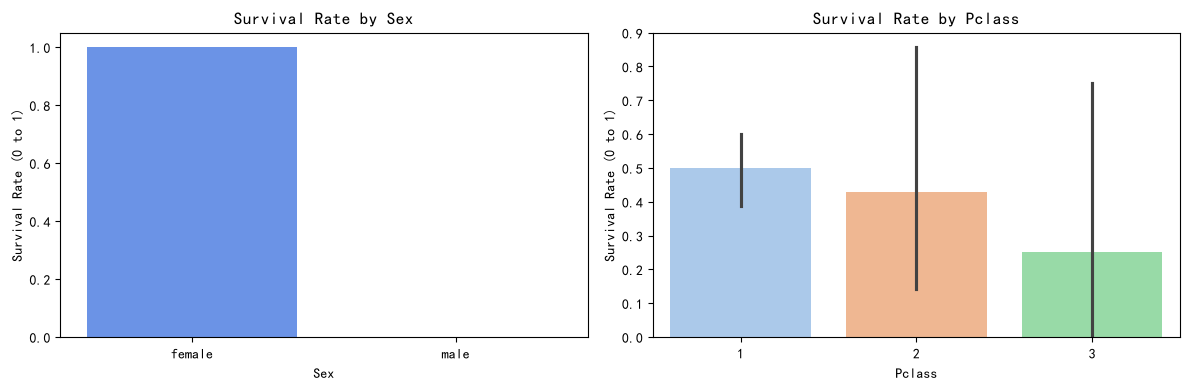

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x="Sex", y="Survived", data=df, ax=axes[0])
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate (0 to 1)")

sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[1], palette="pastel")
axes[1].set_title("Survival Rate by Pclass")
axes[1].set_ylabel("Survival Rate (0 to 1)")

plt.tight_layout()

plt.savefig("../reports/figures/survival_analysis.png", dpi=300, bbox_inches="tight")
print("图片已保存！")

plt.show()

##  数据可视化与结论 (Visualization & Insights)

为了更直观地展示数据，我使用 `seaborn` 绘制了以下图表，并保存至 `reports/figures/` 目录下：

![Survival Analysis](../reports/figures/survival_analysis.png)

**核心发现：**
1. **性别是生存率的第一影响要素**：女性的生存率远远高于男性
2. **舱位等级与生存率呈正相关**：头等舱（Pclass 1）的生存率最高，而三等舱（Pclass 3）的生存率最低。这说明在灾难发生时，社会地位和资源分配严重影响了救援结果。

*(注：以上数据基于所得完整数据集统计)*

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15868\2884226349.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass', y='Age', data=df, palette="Set2")


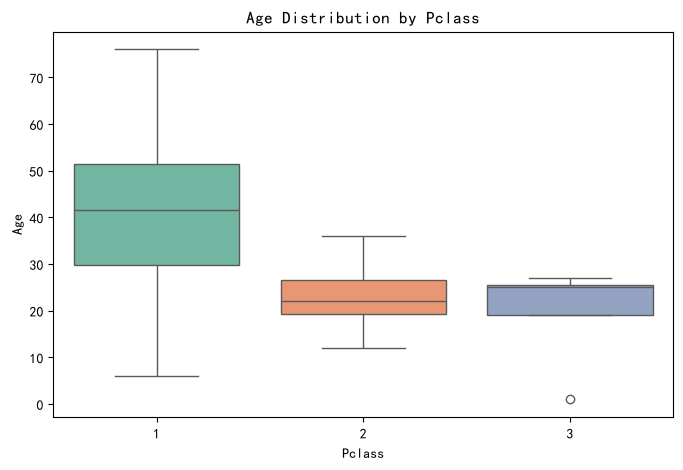

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Pclass', y='Age', data=df, palette="Set2")

plt.title("Age Distribution by Pclass")
plt.xlabel("Pclass")
plt.ylabel("Age")

plt.savefig("../reports/figures/age_by_pclass.png", dpi=300, bbox_inches="tight")
plt.show()

### 年龄与客舱等级的分布 (Age vs. Pclass)

![Age by Pclass](../reports/figures/age_by_pclass.png)

**图表解读：**
从箱线图可以清晰地看出，不同客舱等级的乘客年龄分布存在显著差异：
- **头等舱 (Pclass 1)**：乘客的中位数年龄最大（约 40 岁左右），且整体年龄跨度极大（从 10 多岁到 70 多岁），说明头等舱以中老年富裕阶层为主。
- **二等舱 (Pclass 2)**：中位数年龄在 25-30 岁之间。
- **三等舱 (Pclass 3)**：乘客中位数年龄最小（约 25 岁左右），箱体较扁，说明年轻人居多，最下方的圆圈代表有极少数的小孩。

D:\Users\Lenovo\anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.draw()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15868\1711594049.py:9: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.savefig("../reports/figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
D:\Users\Lenovo\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


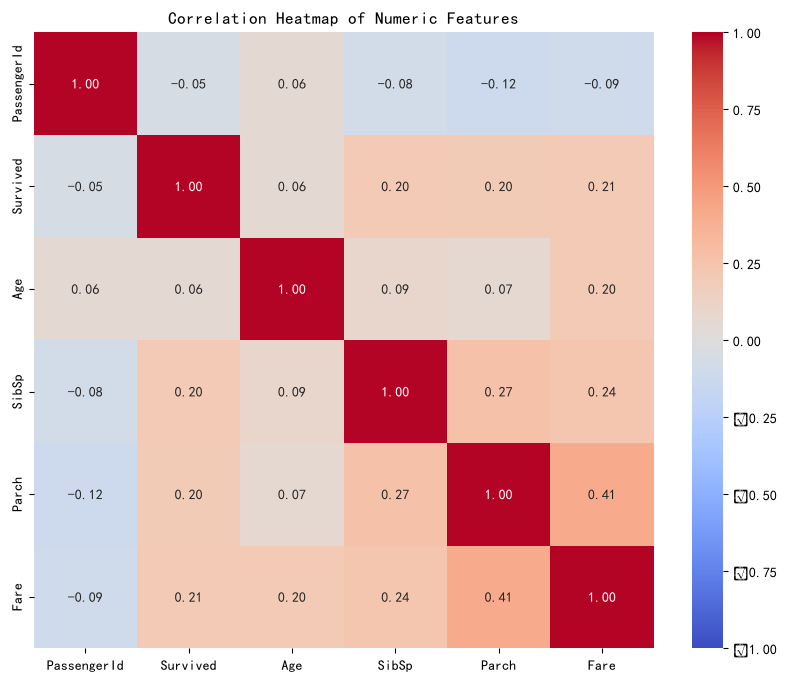

In [7]:
plt.figure(figsize=(10, 8))

corr_matrix = df.corr(numeric_only=True)

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)

plt.title("Correlation Heatmap of Numeric Features")

plt.savefig("../reports/figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### 特征相关性分析 (Correlation Heatmap)

![Correlation Heatmap](../reports/figures/correlation_heatmap.png)

**图表解读：**
热力图中的数值表示两个变量之间的皮尔逊相关系数（范围在 -1 到 1 之间）。颜色越红代表正相关越强，越蓝代表负相关越强。对角线上全为 1.00，因为变量与自己完全相关。

根据当前数值特征的相关性矩阵，我们有以下发现：
- **Fare（票价）与 Survived（生存）呈正相关（0.21）**：说明票价越高的乘客，生存的概率越大（通常对应头等舱乘客）。
- **Fare 与 Parch（父母子女数）呈正相关（0.41）**：这是图里相关性最强的一对变量，说明带父母或子女出行的乘客，倾向于购买更昂贵的舱位，多以富裕家庭为单位出行。
- **SibSp（兄弟姐妹配偶数）与 Parch 呈正相关（0.27）**：符合常理，一般大家庭出行时，这两类亲属都会存在。
- **PassengerId（乘客ID）与其他特征几乎无相关性**：说明 ID 是按顺序随机分配的。在后续的机器学习建模中，我们可以直接删除这一列特征。